In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import qnm_solver as qnm
import pandas as pd
import lal
import pycbc.psd
lal.swig_redirect_standard_output_error(False)

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\boldmath"
})


/tmp/ipykernel_17175/2751596508.py:6: UserWarning: Wswiglal-redir-stdio:
----------------------------------------------------------------
SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
----------------------------------------------------------------

  import lal


In [3]:
#Constants-------
G_SI = 6.67430e-11       # m^3 kg^-1 s^-2
c_SI = 299792458.0       # m s^-1
M_sun = 1.98847e30       # kg
M_p = 6.61*M_sun         #Physical Black hole mass
D_l = 3.27e+19     #source distance (m)
L_m = G_SI*M_p/c_SI**2   #rescaling length
t_m = G_SI*M_p/c_SI**3   #rescaling time

#Parameters------

M = 1       #Dimensionless black hole mass. All other parameters are scaled by the physical mass.
mu = 1e-6 #String tension
E = M * 5    #String energy parameter
l = np.array([2,4,6,8])     #Mode
m = 0       #Mode


Nt = 2500000  #time values 
Nr = 50000   #radial values

#Variables-------

#Coordinates
theta = np.pi/2     #plane of motion 

target_rs_values = [5.5, 4.5, 3.5, 2.5]
r_obs = np.array([100*M, 3500*M])

In [ ]:
res = qnm.zerilli_solver(M, mu, E, l, theta, Nt, Nr, target_rs_values, r_obs)

with open('zer_sol_full.pkl', 'wb') as file:
    pickle.dump(res, file)
#print("Number of result entries:", len(results))
#print("Keys available in a result entry:", results[0].keys())
#print(results[6]["mu"], results[6]["E"])


mu = 1e-06 E 5.0 



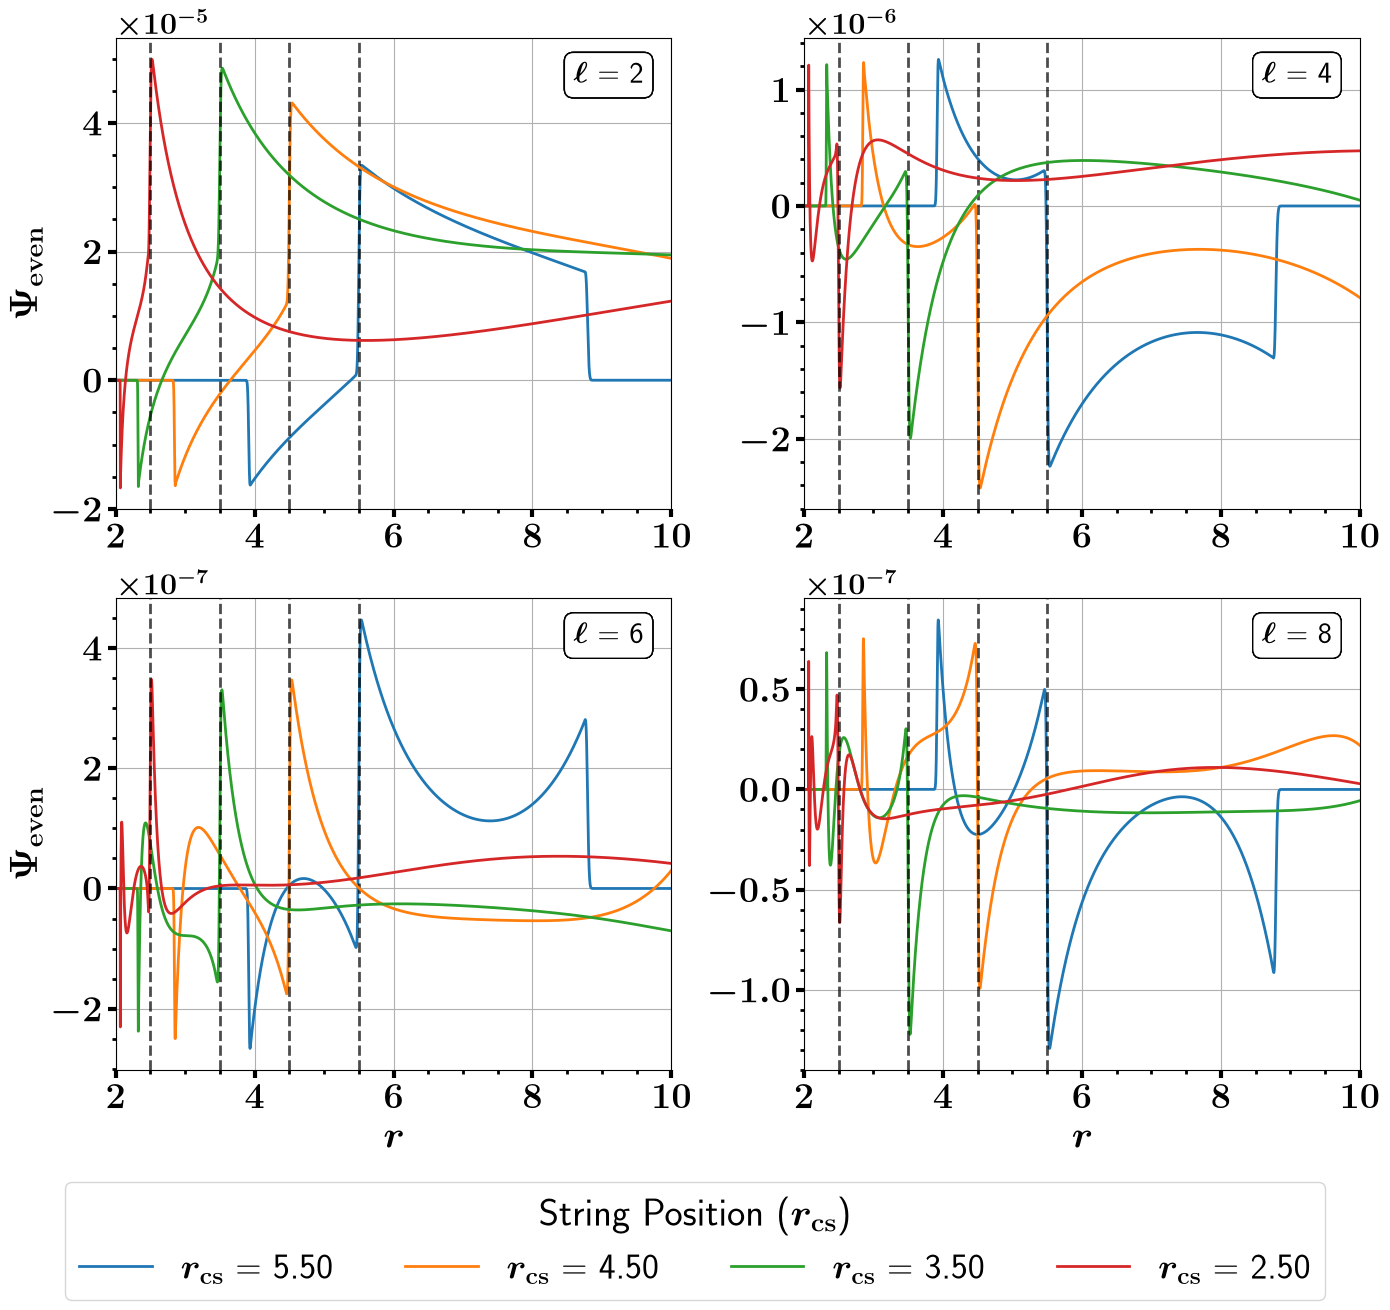

In [4]:
with open('zer_sol_full.pkl', 'rb') as file:
    results = pickle.load(file)
r_i = results[0]["r_i"]
psi_ext = results[0]["psi_ext"]
wave_snapshots = results[0]["wave_snapshots"]
dt = results[0]["dt"]
print("mu =", results[0]["mu"], "E", results[0]["E"], "\n")
fig, axes = plt.subplots(2, 2, squeeze=False, figsize=(14, 12))
axes = axes.flatten()
for idx, l_val in enumerate(l):
    ax = axes[idx]
    for target, (rs, wave_profile) in wave_snapshots.items():

        ax.plot(r_i, wave_profile[idx], label=f"$r_{{\\rm cs}}$ = {rs:.2f}", linewidth=2)
        ax.axvline(rs, linestyle = '--', color = 'black', linewidth = 2.0, alpha = 0.7)
        ax.text(
        0.95, 0.95,                     
        f"$\\ell$ = {l[idx]}",
        transform=ax.transAxes,         
        fontsize=22,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="black",
            alpha=1.0
            ))
        axes[2].set_xlabel("$r$", fontsize = 28)
        axes[3].set_xlabel("$r$", fontsize = 28)
        ax.minorticks_on()
        ax.tick_params(which = 'minor', width = 2, length = 3)
        ax.tick_params(width = 3, length = 6, labelsize = 26)
        axes[0].set_ylabel("$\\Psi_{\\rm even}$", fontsize = 28)
        axes[2].set_ylabel("$\\Psi_{\\rm even}$", fontsize = 28)
        ax.grid(True)
        ax.set_xlim(2, 10)
        ax.yaxis.get_offset_text().set_fontsize(22)  
#fig.supylabel("$\\Psi_{\\rm even}$", fontsize = 20)
plt.tight_layout(rect=[0, 0.02, 1, 1])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=min(len(labels), 4),
    title="String Position ($r_{\\rm cs}$)",
    title_fontsize=28,
    fontsize=26,
)

In [5]:
t_sim = np.arange(Nt) * dt

u_time, psi_even_inf = qnm.psi_at_infinity(M, t_sim, r_obs, psi_ext, l)
h_p_inf = qnm.h_plus_infinity(u_time, psi_even_inf, l, theta)
h_scaled = h_p_inf * (L_m / D_l)

Maximum h_scaled: 1.5862467901421006e-20
Corresponding retarded time index: 87264
Corresponding u_time (dimensionless): -3414.6006975399127


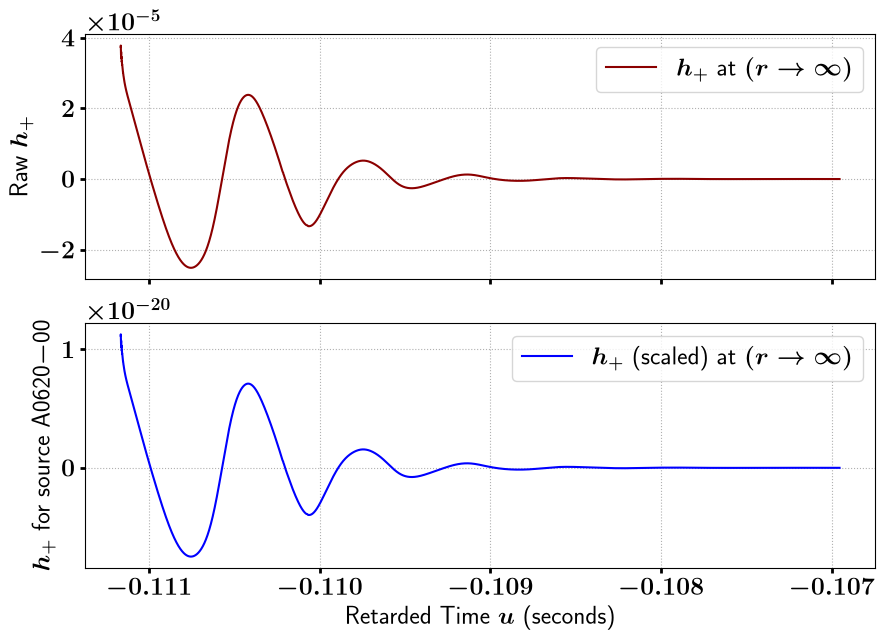

In [6]:
max_idx = np.argmax(np.abs(h_scaled))

max_h = h_scaled[max_idx]
max_u = u_time[max_idx]
print(f"Maximum h_scaled: {max_h}")
print(f"Corresponding retarded time index: {max_idx}")
print(f"Corresponding u_time (dimensionless): {max_u}")

skip_steps = 87500

u_trimmed = u_time[skip_steps:200000]
h_trimmed = h_scaled[skip_steps:200000]
h_p_trimmed = h_p_inf[skip_steps:200000]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ax1.plot(
    u_trimmed * t_m,
    h_p_trimmed,
    color='darkred',
    linewidth=1.5,
    label=r'$h_+$ at $(r \to \infty)$',
)
ax1.tick_params(width = 2, labelsize = 18)
ax1.set_ylabel(r'Raw $h_+$', fontsize=18)
ax1.grid(True, linestyle=':', alpha=1)
ax1.yaxis.get_offset_text().set_fontsize(18)
ax1.legend(loc='upper right', fontsize = 18)

ax2.plot(
    u_trimmed * t_m,
    h_trimmed,
    color='blue',
    linewidth=1.5,
    label=r'$h_+$ (scaled) at $(r \to \infty)$',
)
ax2.set_ylabel(r'$h_+$ for source A0620−00', fontsize=18)
ax2.grid(True, linestyle=':', alpha=1)
ax2.legend(loc='upper right', fontsize = 18)
ax2.yaxis.get_offset_text().set_fontsize(18)
ax2.tick_params(width = 2, labelsize = 18)
plt.xlabel(r'Retarded Time $u$ (seconds)', fontsize=18)
plt.tight_layout()
plt.show()

In [7]:
u_time_sec = u_time * t_m
dt = u_time_sec[1] - u_time_sec[0]
N = len(h_scaled)

# 2. Apply a Hann window (standard in GW data analysis) to taper edges smoothly
#window = np.hanning(N)

#coherent_gain = np.mean(window)

h_windowed = h_scaled

fft_strain_s = np.fft.rfft(h_windowed)
fft_freqs_s = np.fft.rfftfreq(N,d=dt)

amp_spec = np.abs(fft_strain_s)

Optimal SNR: 38.79


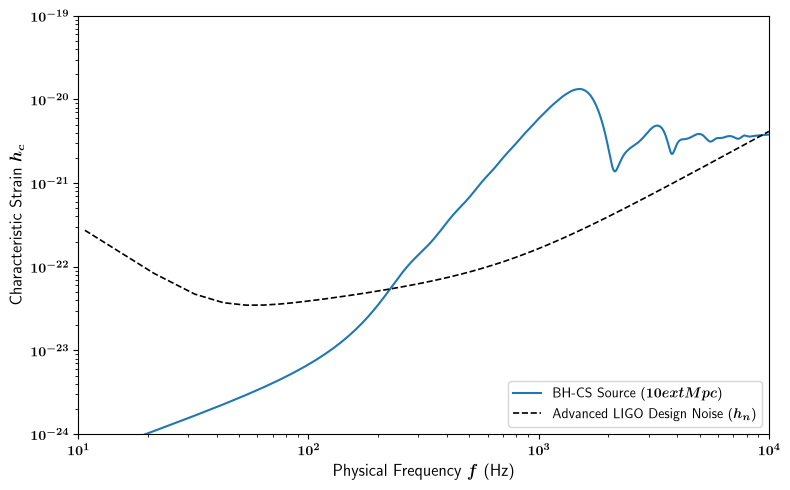

In [8]:
import pycbc.psd
f_nz = fft_freqs_s[1:]
h_characteristic = 2.0 * f_nz * dt * np.abs(fft_strain_s[1:])

flen_s = len(fft_strain_s)
delta_f_s = fft_freqs_s[1] - fft_freqs_s[0]
flow = 10.0
psd = pycbc.psd.aLIGOZeroDetHighPower(flen_s, delta_f_s, flow)

ligo_noise_strain = np.sqrt(f_nz * psd[1:])


valid = (f_nz >= 10.0) & (f_nz <= 10000.0) & (psd[1:] > 0)
snr = np.sqrt(np.sum((h_characteristic[valid] / ligo_noise_strain[valid])**2 * (delta_f_s / f_nz[valid])))

print(f"Optimal SNR: {snr:.2f}")


plt.figure(figsize=(8, 5))
plt.plot(f_nz, h_characteristic, lw=1.5, label='BH-CS Source ($10\text{ Mpc}$)')
plt.plot(f_nz, ligo_noise_strain, color='black', linestyle='--', lw=1.2, label='Advanced LIGO Design Noise ($h_n$)')

plt.xscale('log')
plt.yscale('log')
plt.xlim(10, 1e4)
plt.ylim(10**-24, 10**-19)

plt.xlabel(r'Physical Frequency $f$ (Hz)', fontsize=12)
plt.ylabel(r'Characteristic Strain $h_c$ ', fontsize=12)
#plt.title('Nambu-Goto Signal vs. Official Advanced LIGO Sensitivity', fontsize=14)
#plt.grid(True, which='both', linestyle=':')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [9]:
h_s = []
u_s = []
M_array = [6.61,    #A0620−00
           5.1,      #MAXI J0637−430
           9.1,     #XTE J1550−564    
           7.2,     #GS 2000+25 
           6.98     #LMC X-3
           ]
L_array = [3.27e+19,
           2.68e+20,
           1.35e20,
           8.31e+19,
           1.48e+21
           ]

label = ['A0620−00', 'MAXI J0637−430', 'XTE J1550−564', 'GS 2000+25', 'LMC X-3']

for M, L in zip(M_array, L_array):
    M_kg = M * M_sun
    L_rescale = G_SI*M_kg/c_SI**2   #rescaling length
    t_rescale = G_SI*M_kg/c_SI**3   #rescaling time
    h = h_p_inf * (L_rescale / L)
    u_time_sec = u_time * t_rescale
    h_s.append(h)
    u_s.append(u_time_sec)

h_s = np.array(h_s)
u_s = np.array(u_s)


N = h_s.shape[1]

fft_strain = []
fft_freqs = []
h_char = []
ligo_noise_strain = []
snr_list = []

for i in range(len(M_array)):

    dt = u_s[i, 1] - u_s[i, 0]

    # Hann window
    window = np.hanning(N)

    h_windowed = h_s[i]

    # FFT
    fft = np.fft.rfft(h_windowed)

    freqs = np.fft.rfftfreq(N, d=dt)

    amplitude = np.abs(fft)

    hc = 2.0 * freqs * dt * np.abs(fft)

    flen = len(freqs)
    delta_f = freqs[1] - freqs[0]
    flow = 10.0
    psd = pycbc.psd.aLIGOZeroDetHighPower(flen, delta_f, flow)

    hn = np.sqrt(freqs * np.asarray(psd[:]))
    valid = (freqs >= 10.0) & (freqs <= 10000.0) & (psd[:] > 0)
    snr = np.sqrt(np.sum((hc[valid] / hn[valid])**2 * (delta_f / freqs[valid])))

    fft_strain.append(fft)
    fft_freqs.append(freqs)
    h_char.append(hc)
    snr_list.append(snr)
    ligo_noise_strain.append(hn)

fft_strain = np.array(fft_strain)
fft_freqs = np.array(fft_freqs)

df = pd.DataFrame({'Source': label, 'Mass': M_array, 'Distance': L_array, 'SNR (10-10KHz)': snr_list})
print(df)

           Source  Mass      Distance  SNR (10-10KHz)
0        A0620−00  6.61  3.270000e+19       38.793863
1  MAXI J0637−430  5.10  2.680000e+20        2.646259
2   XTE J1550−564  9.10  1.350000e+20       18.561055
3      GS 2000+25  7.20  8.310000e+19       18.391232
4         LMC X-3  6.98  1.480000e+21        0.965457


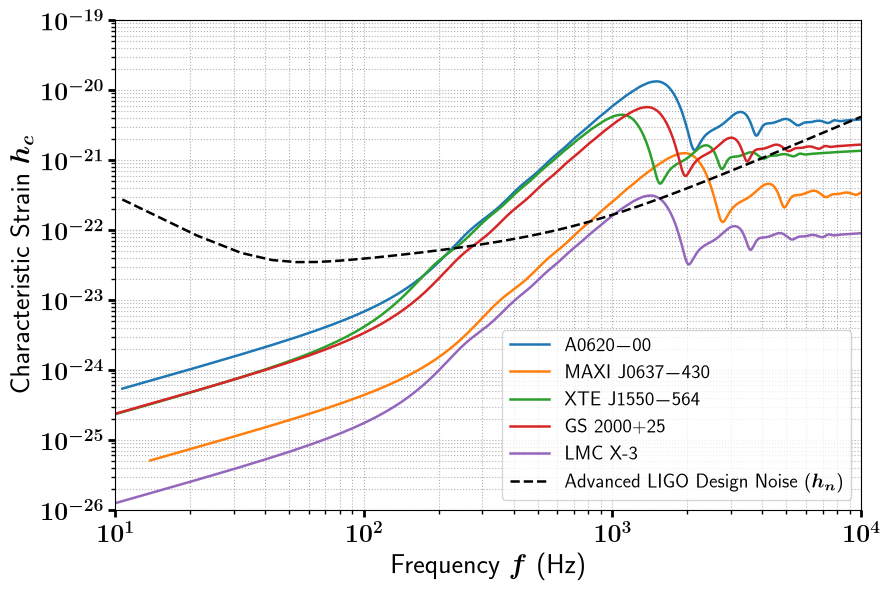

In [10]:
plt.figure(figsize=(9, 6))
for i in range(len(M_array)):
    plt.plot(fft_freqs[i][1:], h_char[i][1:], lw=1.8, label=rf'{label[i]}')
plt.plot(fft_freqs[0][1:], ligo_noise_strain[0][1:], color='black', linestyle='--', lw=1.8, label='Advanced LIGO Design Noise ($h_n$)')

plt.xscale('log')
plt.yscale('log')

plt.ylim(10**-26, 10**-19)
plt.xlim(10, 1e4)
plt.xlabel(r'Frequency $f$ (Hz)', fontsize=20)
plt.ylabel(r'Characteristic Strain $h_c$ ', fontsize=20)
plt.tick_params(width = 2, length = 5, labelsize = 18)
plt.tick_params(which = 'minor', width = 1, length = 3)
#plt.title('Nambu-Goto Signal vs. Official Advanced LIGO Sensitivity', fontsize=14)
plt.grid(True, which='both', linestyle=':')
plt.legend(loc='lower right', fontsize = 14)
plt.tight_layout()
plt.show()

In [55]:
Nt = 20000
Nr = 5000
mu_vals = np.logspace(-11,-6, 100)
E_vals = M*np.linspace(5, 8, 100)

#mu, E = np.meshgrid(mu_vals, E_vals, indexing='ij')

results_mu = qnm.zerilli_solver(M, mu_vals, E, l, theta, Nt, Nr, target_rs_values, r_obs)
#results_E = qnm.zerilli_solver(M, mu, E_vals, l, theta, Nt, Nr, target_rs_values, r_obs)

/home/ishan/py_code/cs_bh/cs_bh_gw/qnm_solver.py:11: RuntimeWarning: invalid value encountered in log
  lambda r: r_star_val - (r + 2 * M * np.log(r / (2.0 * M) - 1.0)),
/home/ishan/py_code/cs_bh/cs_bh_gw/qnm_solver.py:180: RuntimeWarning: overflow encountered in multiply
  V_z_term = V_z[:, 1:-1] * psi_curr[:, 1:-1]
/home/ishan/py_code/cs_bh/cs_bh_gw/qnm_solver.py:185: RuntimeWarning: invalid value encountered in subtract
  + dt**2 * (d2psi_drstar2 - V_z_term + S[:, 1:-1]))


KeyboardInterrupt: 

In [54]:
psi_values = []
#psi_peak = [np.max(np.abs(results_E[i]["psi_ext"])) for i in range(len(E_vals))]
psi_peak2 = [np.max(np.abs(results_mu[i]["psi_ext"])) for i in range(len(mu_vals))]
#strain_peak = np.max(h_scaled)
plt.figure(figsize=(8, 5))

plt.loglog(mu_vals, psi_peak2, linestyle='-', color='b')
plt.xlabel(r'String Tension ($\mu$)', fontsize=16)
plt.ylabel(r'Peak $|\Psi_{\mathrm{ext}}|$', fontsize=16)
plt.grid(True, which="major")
plt.tick_params(width = 2, length = 5, labelsize = 16)
plt.tick_params(which = 'minor', width = 1, length = 3)
plt.show()

#plt.figure(figsize=(8, 5))
#plt.plot(E_vals, psi_peak, linestyle='-', color='r')
#plt.xlabel(r'String Energy Parameter ($E$)', fontsize=16)
#plt.ylabel(r'Peak $|\psi_{\mathrm{ext}}|$', fontsize=16)
#plt.grid(True)
#plt.show()

NameError: name 'mu_vals' is not defined